In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Device:", device)

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Device: cuda


In [ ]:
import os
import zipfile
from tqdm.auto import tqdm

ZIP_PATH = "/content/drive/MyDrive/GSSD.zip"
EXTRACT_PATH = "/content/GSSD"

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    files = zip_ref.infolist()
    print(f"Total files in ZIP: {len(files)}")

    for file in tqdm(files, desc="Extracting GSSD", unit="file"):
        zip_ref.extract(file, EXTRACT_PATH)

print("✅ Extraction completed!")

Total files in ZIP: 3966


Extracting GSSD:   0%|          | 0/3966 [00:00<?, ?file/s]

✅ Extraction completed!


In [ ]:
import os

print("Inside /content/GSSD:")
print(os.listdir("/content/GSSD"))

Inside /content/GSSD:
['GSSD']


In [ ]:
import os

DATA_ROOT = "/content/GSSD/GSSD"

for split in ["train", "val", "test"]:

    image_dir = os.path.join(
        DATA_ROOT,
        split,
        "image"
    )

    mask_dir = os.path.join(
        DATA_ROOT,
        split,
        "mask"
    )

    print(
        split.upper(),
        "| Images:",
        len(os.listdir(image_dir)),
        "| Masks:",
        len(os.listdir(mask_dir))
    )

TRAIN | Images: 1498 | Masks: 1496
VAL | Images: 186 | Masks: 186
TEST | Images: 194 | Masks: 194


In [ ]:
import os
import glob
import re

TRAIN_IMG_DIR = "/content/GSSD/train/image"
TRAIN_MASK_DIR = "/content/GSSD/train/mask"

images = glob.glob(os.path.join(TRAIN_IMG_DIR, "*.tif"))
masks = glob.glob(os.path.join(TRAIN_MASK_DIR, "*.tif"))

print("Raw image files:", len(images))
print("Raw mask files :", len(masks))

def get_id(path):
    filename = os.path.basename(path)
    numbers = re.findall(r"\d+", filename)
    return numbers[-1] if numbers else filename

image_ids = {get_id(f): f for f in images}
mask_ids = {get_id(f): f for f in masks}

print("\nUnique image IDs:", len(image_ids))
print("Unique mask IDs :", len(mask_ids))

missing_masks = set(image_ids) - set(mask_ids)
missing_images = set(mask_ids) - set(image_ids)

print("\nImages with NO matching mask:")
for x in sorted(missing_masks):
    print(os.path.basename(image_ids[x]))

print("\nMasks with NO matching image:")
for x in sorted(missing_images):
    print(os.path.basename(mask_ids[x]))

Raw image files: 0
Raw mask files : 0

Unique image IDs: 0
Unique mask IDs : 0

Images with NO matching mask:

Masks with NO matching image:


In [ ]:
import os

for root, dirs, files in os.walk("/content/GSSD"):

    if os.path.basename(root) in ["image", "mask"]:
        print("FOUND:", root)
        print("Number of files:", len(files))
        print()

FOUND: /content/GSSD/GSSD/val/image
Number of files: 186

FOUND: /content/GSSD/GSSD/val/mask
Number of files: 186

FOUND: /content/GSSD/GSSD/test/image
Number of files: 194

FOUND: /content/GSSD/GSSD/test/mask
Number of files: 194

FOUND: /content/GSSD/GSSD/train/image
Number of files: 1497

FOUND: /content/GSSD/GSSD/train/mask
Number of files: 1496



In [ ]:
import os
import glob
import re

TRAIN_IMG_DIR = "/content/GSSD/GSSD/train/image"
TRAIN_MASK_DIR = "/content/GSSD/GSSD/train/mask"

images = glob.glob(os.path.join(TRAIN_IMG_DIR, "*.tif"))
masks = glob.glob(os.path.join(TRAIN_MASK_DIR, "*.tif"))

print("Image files:", len(images))
print("Mask files :", len(masks))

def get_id(path):
    filename = os.path.basename(path)
    numbers = re.findall(r"\d+", filename)
    return numbers[-1] if numbers else filename

image_ids = {get_id(f): f for f in images}
mask_ids = {get_id(f): f for f in masks}

missing_masks = set(image_ids.keys()) - set(mask_ids.keys())
missing_images = set(mask_ids.keys()) - set(image_ids.keys())

print("\nImages without matching masks:")
for x in sorted(missing_masks):
    print("ID:", x, "| File:", os.path.basename(image_ids[x]))

print("\nMasks without matching images:")
for x in sorted(missing_images):
    print("ID:", x, "| File:", os.path.basename(mask_ids[x]))

Image files: 1496
Mask files : 1496

Images without matching masks:

Masks without matching images:


In [ ]:
from huggingface_hub import snapshot_download

PRITHVI_DIR = "/content/prithvi-600m"

model_dir = snapshot_download(
    repo_id="ibm-nasa-geospatial/Prithvi-EO-2.0-600M",
    local_dir=PRITHVI_DIR
)

print("Prithvi downloaded to:")
print(model_dir)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Prithvi downloaded to:
/content/prithvi-600m


In [ ]:
import sys

sys.path.insert(
    0,
    PRITHVI_DIR
)

from prithvi_mae import PrithviViT

print(
    "PrithviViT imported successfully!"
)

PrithviViT imported successfully!


In [ ]:
import torch

model = PrithviViT(
    img_size=448,
    patch_size=(1, 14, 14),
    num_frames=1,
    in_chans=6,
    embed_dim=1280,
    depth=32,
    num_heads=16,
    mlp_ratio=4.0,
    coords_encoding=[],
)

print(
    "Prithvi encoder created."
)

print(
    "Parameters:",
    sum(
        p.numel()
        for p in model.parameters()
    ) / 1e6,
    "M"
)

Prithvi encoder created.
Parameters: 631.18848 M


In [ ]:
import torch

PRITHVI_CHECKPOINT = (
    f"{PRITHVI_DIR}/Prithvi_EO_V2_600M.pt"
)

checkpoint = torch.load(
    PRITHVI_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

print(
    "Checkpoint keys:",
    len(checkpoint)
)

Checkpoint keys: 494


In [ ]:
encoder_state = {}

for key, value in checkpoint.items():

    if key.startswith("encoder."):

        new_key = key[
            len("encoder.") :
        ]

        encoder_state[new_key] = value


missing_keys, unexpected_keys = (
    model.load_state_dict(
        encoder_state,
        strict=False
    )
)

print(
    "Pretrained Prithvi weights loaded."
)

print(
    "Missing keys:",
    len(missing_keys)
)

print(
    "Unexpected keys:",
    len(unexpected_keys)
)

Pretrained Prithvi weights loaded.
Missing keys: 0
Unexpected keys: 0


In [ ]:
del checkpoint
del encoder_state

import gc

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(
    "Pretrained checkpoint released from RAM."
)

Pretrained checkpoint released from RAM.


In [ ]:
def prithvi_features(model, x):

    """
    Extract multi-scale Prithvi features
    from transformer blocks:

    7
    15
    23
    31
    """

    # Input:
    # [B, C, H, W]
    #
    # Prithvi patch embedding expects:
    # [B, C, T, H, W]
    #
    # We have one temporal frame.

    if (
        len(x.shape) == 4
        and
        model.patch_embed.input_size[0] == 1
    ):

        x = x.unsqueeze(2)

    sample_shape = x.shape[-3:]

    # Patch embedding
    x = model.patch_embed(x)

    # Positional embedding
    pos_embed = (
        model.interpolate_pos_encoding(
            sample_shape
        )
    )

    x = x + pos_embed[:, 1:, :]

    # No temporal/location encoding
    # No random masking for segmentation

    # CLS token
    cls_token = (
        model.cls_token
        +
        pos_embed[:, :1, :]
    )

    cls_tokens = cls_token.expand(
        x.shape[0],
        -1,
        -1
    )

    x = torch.cat(
        (cls_tokens, x),
        dim=1
    )

    features = []

    # Transformer blocks
    for i, block in enumerate(
        model.blocks
    ):

        x = block(x)

        if i in [
            7,
            15,
            23,
            31
        ]:

            features.append(x)

    # Final normalization
    x = model.norm(x)

    return features

In [ ]:
def tokens_to_feature_maps(features):

    spatial_features = []

    for f in features:

        # Remove CLS token
        f = f[:, 1:, :]

        B, N, C = f.shape

        H = W = int(
            N ** 0.5
        )

        # [B, N, C]
        # ↓
        # [B, C, N]

        f = f.transpose(
            1,
            2
        )

        # ↓
        # [B, C, H, W]

        f = f.reshape(
            B,
            C,
            H,
            W
        )

        spatial_features.append(
            f
        )

    return spatial_features

In [ ]:
import torch.nn as nn
import torch.nn.functional as F


def make_norm(channels):

    # Stable for batch size = 1

    groups = (
        32
        if channels >= 32
        else 1
    )

    return nn.GroupNorm(
        groups,
        channels
    )


In [ ]:
class ConvModule(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=3
    ):

        super().__init__()

        padding = (
            kernel_size // 2
        )

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size,
                padding=padding,
                bias=False
            ),

            make_norm(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            )
        )


    def forward(self, x):

        return self.block(x)

In [ ]:
class PyramidPoolingModule(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        pool_scales=(
            1,
            2,
            3,
            6
        )
    ):

        super().__init__()

        self.pool_scales = (
            pool_scales
        )

        self.convs = (
            nn.ModuleList([

                nn.Sequential(

                    nn.Conv2d(
                        in_channels,
                        out_channels,
                        kernel_size=1,
                        bias=False
                    ),

                    make_norm(
                        out_channels
                    ),

                    nn.ReLU(
                        inplace=True
                    )

                )

                for _ in pool_scales

            ])
        )


        self.bottleneck = (
            ConvModule(

                in_channels
                +
                len(pool_scales)
                *
                out_channels,

                out_channels,

                kernel_size=3
            )
        )


    def forward(self, x):

        outputs = [x]


        for scale, conv in zip(

            self.pool_scales,

            self.convs

        ):

            pooled = (
                F.adaptive_avg_pool2d(

                    x,

                    output_size=(
                        scale,
                        scale
                    )
                )
            )


            pooled = conv(
                pooled
            )


            pooled = (
                F.interpolate(

                    pooled,

                    size=x.shape[-2:],

                    mode="bilinear",

                    align_corners=False

                )
            )


            outputs.append(
                pooled
            )


        x = torch.cat(

            outputs,

            dim=1

        )


        return self.bottleneck(
            x
        )

In [ ]:
class UPerNetDecoder(nn.Module):

    def __init__(

        self,

        in_channels=1280,

        decoder_channels=256,

        num_classes=2

    ):

        super().__init__()


        # PPM

        self.ppm = (
            PyramidPoolingModule(

                in_channels,

                decoder_channels

            )
        )


        # Lateral convolutions

        self.lateral_convs = (
            nn.ModuleList([

                ConvModule(

                    in_channels,

                    decoder_channels,

                    kernel_size=1

                )

                for _ in range(3)

            ])
        )


        # FPN convolutions

        self.fpn_convs = (
            nn.ModuleList([

                ConvModule(

                    decoder_channels,

                    decoder_channels,

                    kernel_size=3

                )

                for _ in range(4)

            ])
        )


        # FPN bottleneck

        self.fpn_bottleneck = (
            ConvModule(

                decoder_channels * 4,

                decoder_channels,

                kernel_size=3

            )
        )


        # Segmentation head

        self.classifier = (
            nn.Sequential(

                nn.Conv2d(

                    decoder_channels,

                    128,

                    kernel_size=3,

                    padding=1

                ),

                make_norm(
                    128
                ),

                nn.ReLU(
                    inplace=True
                ),


                nn.Conv2d(

                    128,

                    64,

                    kernel_size=3,

                    padding=1

                ),

                make_norm(
                    64
                ),

                nn.ReLU(
                    inplace=True
                ),


                nn.Dropout2d(
                    0.1
                ),


                nn.Conv2d(

                    64,

                    num_classes,

                    kernel_size=1

                )

            )
        )


    def forward(
        self,
        features
    ):


        c1, c2, c3, c4 = (
            features
        )


        # PPM only on deepest feature

        p4 = self.ppm(
            c4
        )


        # Lateral features

        l1 = (
            self.lateral_convs[0](
                c1
            )
        )


        l2 = (
            self.lateral_convs[1](
                c2
            )
        )


        l3 = (
            self.lateral_convs[2](
                c3
            )
        )


        # Top-down FPN


        l3 = l3 + (
            F.interpolate(

                p4,

                size=l3.shape[-2:],

                mode="bilinear",

                align_corners=False

            )
        )


        l2 = l2 + (
            F.interpolate(

                l3,

                size=l2.shape[-2:],

                mode="bilinear",

                align_corners=False

            )
        )


        l1 = l1 + (
            F.interpolate(

                l2,

                size=l1.shape[-2:],

                mode="bilinear",

                align_corners=False

            )
        )


        # FPN refinement


        f1 = self.fpn_convs[0](
            l1
        )

        f2 = self.fpn_convs[1](
            l2
        )

        f3 = self.fpn_convs[2](
            l3
        )

        f4 = self.fpn_convs[3](
            p4
        )


        target_size = (
            f1.shape[-2:]
        )


        f2 = F.interpolate(

            f2,

            size=target_size,

            mode="bilinear",

            align_corners=False

        )


        f3 = F.interpolate(

            f3,

            size=target_size,

            mode="bilinear",

            align_corners=False

        )


        f4 = F.interpolate(

            f4,

            size=target_size,

            mode="bilinear",

            align_corners=False

        )


        # Concatenate all levels


        x = torch.cat(

            [
                f1,
                f2,
                f3,
                f4
            ],

            dim=1

        )


        x = self.fpn_bottleneck(
            x
        )


        return self.classifier(
            x
        )

In [ ]:
decoder = UPerNetDecoder(

    in_channels=1280,

    decoder_channels=256,

    num_classes=2

)

print(

    "Decoder parameters:",

    sum(
        p.numel()
        for p in decoder.parameters()
    )
    /
    1e6,

    "M"

)

Decoder parameters: 12.69677 M


In [ ]:
model = model.float()

decoder = decoder.float()

print(
    "Encoder dtype:",
    next(
        model.parameters()
    ).dtype
)

print(
    "Decoder dtype:",
    next(
        decoder.parameters()
    ).dtype
)

Encoder dtype: torch.float32
Decoder dtype: torch.float32


In [ ]:
class PrithviUPerNet(nn.Module):

    def __init__(
        self,
        encoder,
        decoder
    ):

        super().__init__()

        self.encoder = encoder

        self.decoder = decoder


    def forward(
        self,
        x
    ):


        features = (
            prithvi_features(

                self.encoder,

                x

            )
        )


        features = (
            tokens_to_feature_maps(

                features

            )
        )


        logits = self.decoder(

            features

        )


        logits = F.interpolate(

            logits,

            size=x.shape[-2:],

            mode="bilinear",

            align_corners=False

        )


        return logits

In [ ]:
net = PrithviUPerNet(

    model,

    decoder

).to(
    device
)

print(
    "Network created!"
)

Network created!


In [ ]:
import os
import glob
import numpy as np
import torch
import rasterio

from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F


class GSSDDataset(Dataset):

    def __init__(
        self,
        root="/content/GSSD/GSSD",
        split="train",
        augment=False
    ):

        # Image directory
        self.image_dir = os.path.join(
            root,
            split,
            "image"
        )

        # Mask directory
        self.mask_dir = os.path.join(
            root,
            split,
            "mask"
        )

        self.augment = augment


        # Get all image TIFF files
        self.image_files = sorted(

            glob.glob(
                os.path.join(
                    self.image_dir,
                    "image*.tif"
                )
            ),

            key=lambda x: int(
                os.path.basename(x)
                .replace("image", "")
                .replace(".tif", "")
            )
        )


        # Create corresponding mask paths
        self.mask_files = [

            os.path.join(
                self.mask_dir,

                "mask" +

                os.path.basename(x)
                .replace("image", "")
            )

            for x in self.image_files
        ]


        # Check that every image has a mask
        for img, mask in zip(
            self.image_files,
            self.mask_files
        ):

            if not os.path.exists(mask):

                raise FileNotFoundError(
                    f"Missing mask for:\n"
                    f"Image: {img}\n"
                    f"Expected mask: {mask}"
                )


        print(
            f"{split.upper()} dataset loaded: "
            f"{len(self.image_files)} samples"
        )


    def __len__(self):

        return len(self.image_files)


    def __getitem__(self, idx):


        # --------------------------------
        # Read first 6 spectral bands
        # --------------------------------

        with rasterio.open(
            self.image_files[idx]
        ) as src:

            image = src.read(
                [
                    1,  # Blue
                    2,  # Green
                    3,  # Red
                    4,  # NIR
                    5,  # SWIR1
                    6   # SWIR2
                ]
            ).astype(np.float32)


        # --------------------------------
        # Read ground-truth mask
        # --------------------------------

        with rasterio.open(
            self.mask_files[idx]
        ) as src:

            mask = src.read(
                1
            ).astype(np.float32)


        # --------------------------------
        # Convert NumPy → PyTorch tensors
        # --------------------------------

        image = torch.from_numpy(
            image
        )

        mask = torch.from_numpy(
            mask
        )


        # --------------------------------
        # Resize image
        #
        # [6, 512, 512]
        #       ↓
        # [6, 448, 448]
        # --------------------------------

        image = F.interpolate(

            image.unsqueeze(0),

            size=(448, 448),

            mode="bilinear",

            align_corners=False

        ).squeeze(0)


        # --------------------------------
        # Resize mask
        #
        # [512, 512]
        #       ↓ unsqueeze
        # [1, 1, 512, 512]
        #       ↓ resize
        # [1, 1, 448, 448]
        #       ↓ squeeze
        # [448, 448]
        # --------------------------------

        mask = F.interpolate(

            mask
            .unsqueeze(0)
            .unsqueeze(0),

            size=(448, 448),

            mode="nearest"

        )

        mask = mask.squeeze(0).squeeze(0)


        # --------------------------------
        # Data augmentation
        # Training only
        # --------------------------------

        if self.augment:


            # Horizontal flip
            if torch.rand(1).item() < 0.5:

                image = torch.flip(
                    image,
                    dims=[2]
                )

                mask = torch.flip(
                    mask,
                    dims=[1]
                )


            # Vertical flip
            if torch.rand(1).item() < 0.5:

                image = torch.flip(
                    image,
                    dims=[1]
                )

                mask = torch.flip(
                    mask,
                    dims=[0]
                )


        # --------------------------------
        # Convert mask to binary classes
        # --------------------------------

        mask = (
            mask > 0.5
        ).long()


        return (
            image,
            mask
        )

In [ ]:
train_dataset = GSSDDataset(
    root="/content/GSSD/GSSD",
    split="train",
    augment=True
)

image, mask = train_dataset[0]

print("Image shape:", image.shape)
print("Mask shape :", mask.shape)
print("Image dtype:", image.dtype)
print("Mask dtype :", mask.dtype)

print("Mask unique values:", torch.unique(mask))

TRAIN dataset loaded: 1496 samples
Image shape: torch.Size([6, 448, 448])
Mask shape : torch.Size([448, 448])
Image dtype: torch.float32
Mask dtype : torch.int64
Mask unique values: tensor([0, 1])


In [ ]:
train_dataset = GSSDDataset(

    split="train",

    augment=True

)


val_dataset = GSSDDataset(

    split="val",

    augment=False

)


test_dataset = GSSDDataset(

    split="test",

    augment=False

)


print(
    "Train:",
    len(train_dataset)
)

print(
    "Val:",
    len(val_dataset)
)

print(
    "Test:",
    len(test_dataset)
)

TRAIN dataset loaded: 1496 samples
VAL dataset loaded: 186 samples
TEST dataset loaded: 194 samples
Train: 1496
Val: 186
Test: 194


In [ ]:
BATCH_SIZE = 1


train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True

)


val_loader = DataLoader(

    val_dataset,

    batch_size=1,

    shuffle=False,

    num_workers=2,

    pin_memory=True

)


test_loader = DataLoader(

    test_dataset,

    batch_size=1,

    shuffle=False,

    num_workers=2,

    pin_memory=True

)


print(
    "Loaders ready."
)

Loaders ready.


In [ ]:
class FocalLoss(
    nn.Module
):


    def __init__(

        self,

        alpha=0.25,

        gamma=2.0

    ):

        super().__init__()


        self.alpha = (
            alpha
        )


        self.gamma = (
            gamma
        )


    def forward(

        self,

        logits,

        targets

    ):


        ce = F.cross_entropy(

            logits,

            targets,

            reduction="none"

        )


        pt = torch.exp(
            -ce
        )


        focal = (

            self.alpha

            *

            (
                1 - pt
            )

            **

            self.gamma

            *

            ce

        )


        return focal.mean()

In [ ]:
criterion = FocalLoss(

    alpha=0.25,

    gamma=2.0

)

print(
    "Focal Loss ready."
)

Focal Loss ready.


In [ ]:
optimizer = torch.optim.AdamW(

    [

        {

            "params":

            net.encoder.parameters(),

            "lr":

            1e-5

        },

        {

            "params":

            net.decoder.parameters(),

            "lr":

            1e-4

        }

    ],

    weight_decay=0.01

)


print(
    "Optimizer ready."
)

Optimizer ready.


In [ ]:
scaler = torch.amp.GradScaler(

    "cuda"

)

print(
    "GradScaler ready."
)

GradScaler ready.


In [ ]:
RESUME_CHECKPOINT = (

    "/content/drive/MyDrive/"

    "prithvi_upernet_best.pth"

)


print(

    "Checkpoint exists:",

    os.path.exists(
        RESUME_CHECKPOINT
    )

)

Checkpoint exists: True


In [ ]:
resume_checkpoint = torch.load(

    RESUME_CHECKPOINT,

    map_location="cpu"

)


# -----------------------------
# Restore model weights
# -----------------------------

result = net.load_state_dict(

    resume_checkpoint[
        "model_state_dict"
    ],

    strict=True

)


print(
    "Model weights loaded!"
)

print(
    "Missing keys:",
    result.missing_keys
)

print(
    "Unexpected keys:",
    result.unexpected_keys
)


# -----------------------------
# Restore optimizer state
# -----------------------------

optimizer.load_state_dict(

    resume_checkpoint[
        "optimizer_state_dict"
    ]

)

print(
    "Optimizer state restored!"
)


# -----------------------------
# Restore GradScaler state
# -----------------------------

scaler.load_state_dict(

    resume_checkpoint[
        "scaler_state_dict"
    ]

)

print(
    "GradScaler state restored!"
)

Model weights loaded!
Missing keys: []
Unexpected keys: []
Optimizer state restored!
GradScaler state restored!


In [ ]:
start_epoch = (

    resume_checkpoint[
        "epoch"
    ]

)


best_miou = (

    resume_checkpoint[
        "val_miou"
    ]

)


best_f1 = (

    resume_checkpoint[
        "val_f1"
    ]

)


print(
    "🔥 CHECKPOINT INFORMATION"
)

print(
    "Checkpoint epoch:",
    start_epoch
)

print(
    "Best validation mIoU:",
    best_miou
)

print(
    "Validation F1:",
    best_f1
)

🔥 CHECKPOINT INFORMATION
Checkpoint epoch: 10
Best validation mIoU: 0.7299444475161132
Validation F1: 0.6721797486148247


In [ ]:
for state in optimizer.state.values():

    for key, value in state.items():

        if torch.is_tensor(
            value
        ):

            state[key] = value.to(
                device
            )


print(
    "Optimizer tensors moved to device."
)

Optimizer tensors moved to device.


In [ ]:
del resume_checkpoint

import gc

gc.collect()

torch.cuda.empty_cache()


print(
    "Checkpoint RAM released."
)

Checkpoint RAM released.


In [ ]:
def segmentation_metrics(logits, targets):

    preds = logits.argmax(dim=1)

    pred = preds.flatten()
    target = targets.flatten()

    # Background
    bg_intersection = (
        ((pred == 0) & (target == 0))
        .sum()
        .float()
    )

    bg_union = (
        ((pred == 0) | (target == 0))
        .sum()
        .float()
    )

    # Debris / Glacier
    debris_intersection = (
        ((pred == 1) & (target == 1))
        .sum()
        .float()
    )

    debris_union = (
        ((pred == 1) | (target == 1))
        .sum()
        .float()
    )

    debris_pred = (
        (pred == 1)
        .sum()
        .float()
    )

    debris_true = (
        (target == 1)
        .sum()
        .float()
    )

    precision = (
        debris_intersection /
        (debris_pred + 1e-7)
    )

    recall = (
        debris_intersection /
        (debris_true + 1e-7)
    )

    f1 = (
        2 * precision * recall /
        (precision + recall + 1e-7)
    )

    iou_bg = (
        bg_intersection /
        (bg_union + 1e-7)
    )

    iou_debris = (
        debris_intersection /
        (debris_union + 1e-7)
    )

    # CORRECT mean IoU
    miou = (
        iou_bg + iou_debris
    ) / 2.0

    return {
        "iou": iou_debris.item(),
        "miou": miou.item(),
        "precision": precision.item(),
        "recall": recall.item(),
        "f1": f1.item()
    }

In [ ]:
def train_one_epoch(

    net,

    loader,

    optimizer,

    criterion,

    scaler,

    accumulation_steps=8

):


    net.train()


    running_loss = 0.0


    optimizer.zero_grad(

        set_to_none=True

    )


    for step, (

        images,

        masks

    ) in enumerate(
        loader
    ):


        images = images.to(

            device,

            non_blocking=True

        )


        masks = masks.to(

            device,

            non_blocking=True

        )


        with torch.autocast(

            device_type="cuda",

            dtype=torch.float16

        ):


            logits = net(
                images
            )


            loss = criterion(

                logits,

                masks

            )


            loss = (

                loss

                /

                accumulation_steps

            )


        scaler.scale(
            loss
        ).backward()


        if (

            (
                step + 1
            )

            %

            accumulation_steps

            == 0

            or

            (
                step + 1
            )

            ==

            len(loader)

        ):


            scaler.unscale_(
                optimizer
            )


            torch.nn.utils.clip_grad_norm_(

                net.parameters(),

                max_norm=1.0

            )


            scaler.step(
                optimizer
            )


            scaler.update()


            optimizer.zero_grad(

                set_to_none=True

            )


        running_loss += (

            loss.item()

            *

            accumulation_steps

        )


        if step % 50 == 0:


            print(

                f"Step {step}/{len(loader)} "

                f"Loss: "

                f"{loss.item() * accumulation_steps:.4f}"

            )


    return (

        running_loss

        /

        len(loader)

    )

In [ ]:
@torch.no_grad()

def validate(

    net,

    loader,

    criterion

):


    net.eval()


    total_loss = 0.0


    metrics = {

        "iou": 0.0,

        "miou": 0.0,

        "precision": 0.0,

        "recall": 0.0,

        "f1": 0.0

    }


    count = 0


    for images, masks in loader:


        images = images.to(

            device,

            non_blocking=True

        )


        masks = masks.to(

            device,

            non_blocking=True

        )


        with torch.autocast(

            device_type="cuda",

            dtype=torch.float16

        ):


            logits = net(
                images
            )


            loss = criterion(

                logits,

                masks

            )


        total_loss += (
            loss.item()
        )


        batch_metrics = (

            segmentation_metrics(

                logits,

                masks

            )

        )


        for key in metrics:

            metrics[key] += (

                batch_metrics[key]

            )


        count += 1


    for key in metrics:

        metrics[key] /= count


    return (

        total_loss / count,

        metrics

    )

In [ ]:
NEW_BEST_PATH = (

    "/content/drive/MyDrive/"

    "prithvi_upernet_best_resumed.pth"

)


print(

    "New checkpoint will save to:",

    NEW_BEST_PATH

)

New checkpoint will save to: /content/drive/MyDrive/prithvi_upernet_best_resumed.pth


In [ ]:
criterion = FocalLoss(
    alpha=0.25,
    gamma=2.0
)

In [ ]:
TOTAL_EPOCHS = 30


for epoch in range(

    start_epoch,

    TOTAL_EPOCHS

):


    print(

        "\n"

        +

        "=" * 60

    )


    print(

        f"EPOCH "

        f"{epoch + 1}"

        f"/"

        f"{TOTAL_EPOCHS}"

    )


    print(

        "=" * 60

    )


    # -------------------------
    # TRAINING
    # -------------------------


    train_loss = (

        train_one_epoch(

            net,

            train_loader,

            optimizer,

            criterion,

            scaler,

            accumulation_steps=8

        )

    )


    # -------------------------
    # VALIDATION
    # -------------------------


    val_loss, val_metrics = (

        validate(

            net,

            val_loader,

            criterion

        )

    )


    print(
        "\nResults:"
    )


    print(

        f"Train Loss : "

        f"{train_loss:.5f}"

    )


    print(

        f"Val Loss   : "

        f"{val_loss:.5f}"

    )


    print(

        f"Val IoU    : "

        f"{val_metrics['iou']:.4f}"

    )


    print(

        f"Val mIoU   : "

        f"{val_metrics['miou']:.4f}"

    )


    print(

        f"Val F1     : "

        f"{val_metrics['f1']:.4f}"

    )


    print(

        f"Precision  : "

        f"{val_metrics['precision']:.4f}"

    )


    print(

        f"Recall     : "

        f"{val_metrics['recall']:.4f}"

    )


    # -------------------------
    # SAVE NEW BEST MODEL
    # -------------------------


    if (

        val_metrics["miou"]

        >

        best_miou

    ):


        best_miou = (

            val_metrics["miou"]

        )


        torch.save(

            {

                "epoch":

                epoch + 1,


                "model_state_dict":

                net.state_dict(),


                "optimizer_state_dict":

                optimizer.state_dict(),


                "scaler_state_dict":

                scaler.state_dict(),


                "val_miou":

                best_miou,


                "val_f1":

                val_metrics["f1"]

            },


            NEW_BEST_PATH

        )


        print(

            "\n🔥 NEW BEST MODEL!"

        )


        print(

            f"mIoU = "

            f"{best_miou:.4f}"

        )


print(

    "\n🔥 TRAINING COMPLETE."

)


print(

    "Best validation mIoU:",

    best_miou

)


EPOCH 11/30
Step 0/1496 Loss: 0.0062
Step 50/1496 Loss: 0.0059
Step 100/1496 Loss: 0.0068
Step 150/1496 Loss: 0.0034
Step 200/1496 Loss: 0.0078
Step 250/1496 Loss: 0.0122
Step 300/1496 Loss: 0.0079
Step 350/1496 Loss: 0.0065
Step 400/1496 Loss: 0.0058
Step 450/1496 Loss: 0.0061
Step 500/1496 Loss: 0.0061
Step 550/1496 Loss: 0.0131
Step 600/1496 Loss: 0.0070
Step 650/1496 Loss: 0.0054
Step 700/1496 Loss: 0.0046
Step 750/1496 Loss: 0.0036
Step 800/1496 Loss: 0.0113
Step 850/1496 Loss: 0.0147
Step 900/1496 Loss: 0.0067
Step 950/1496 Loss: 0.0128
Step 1000/1496 Loss: 0.0026
Step 1050/1496 Loss: 0.0088
Step 1100/1496 Loss: 0.0105
Step 1150/1496 Loss: 0.0062
Step 1200/1496 Loss: 0.0024
Step 1250/1496 Loss: 0.0041
Step 1300/1496 Loss: 0.0058
Step 1350/1496 Loss: 0.0080
Step 1400/1496 Loss: 0.0049
Step 1450/1496 Loss: 0.0087

Results:
Train Loss : 0.00740
Val Loss   : 0.01213
Val IoU    : 0.5585
Val mIoU   : 0.7385
Val F1     : 0.6900
Precision  : 0.7377
Recall     : 0.6829

🔥 NEW BEST MODEL!

KeyboardInterrupt: 

In [ ]:
### CODE TO TEST THE MODEL
## Actually the testing is done using the checkpoint file which is already created.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os

import gc
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

print("Ready.")

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB
Ready.


In [ ]:
import os
import glob
import gc
import math

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import rasterio

from torch.utils.data import Dataset, DataLoader

In [ ]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Using device:", device)

Using device: cuda


In [ ]:
import zipfile
import os

GSSD_ZIP = "/content/drive/MyDrive/GSSD.zip"
EXTRACT_ROOT = "/content/GSSD"

print("ZIP exists:", os.path.exists(GSSD_ZIP))

if not os.path.exists(GSSD_ZIP):
    raise FileNotFoundError(
        f"GSSD ZIP not found:\n{GSSD_ZIP}\n\n"
        "Change GSSD_ZIP to the actual location of your GSSD.zip."
    )

if not os.path.exists(EXTRACT_ROOT):

    print("Extracting GSSD...")

    with zipfile.ZipFile(
        GSSD_ZIP,
        "r"
    ) as zip_ref:

        zip_ref.extractall(
            EXTRACT_ROOT
        )

    print("GSSD extraction complete.")

else:

    print(
        "GSSD extraction folder already exists."
    )

ZIP exists: True
Extracting GSSD...
GSSD extraction complete.


In [ ]:
DATA_ROOT = "/content/GSSD/GSSD"

print("DATA_ROOT exists:", os.path.exists(DATA_ROOT))

for split in ["train", "val", "test"]:

    image_dir = os.path.join(
        DATA_ROOT,
        split,
        "image"
    )

    mask_dir = os.path.join(
        DATA_ROOT,
        split,
        "mask"
    )

    print(
        split,
        "images:",
        len(
            glob.glob(
                os.path.join(
                    image_dir,
                    "image*.tif"
                )
            )
        ),
        "masks:",
        len(
            glob.glob(
                os.path.join(
                    mask_dir,
                    "mask*.tif"
                )
            )
        )
    )

DATA_ROOT exists: True
train images: 1496 masks: 1496
val images: 186 masks: 186
test images: 194 masks: 194


In [ ]:
from huggingface_hub import snapshot_download

In [ ]:
PRITHVI_DIR = "/content/prithvi-600m"

if not os.path.exists(PRITHVI_DIR):

    print(
        "Downloading Prithvi-EO-2.0-600M..."
    )

    model_dir = snapshot_download(
        repo_id="ibm-nasa-geospatial/Prithvi-EO-2.0-600M",
        local_dir=PRITHVI_DIR
    )

    print(
        "Prithvi downloaded to:",
        model_dir
    )

else:

    print(
        "Prithvi directory already exists:"
    )

    print(PRITHVI_DIR)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Prithvi downloaded to: /content/prithvi-600m


In [ ]:
import os
import sys

print("Current directory:")
print(os.getcwd())

print("\n/content/prithvi-600m exists:")
print(os.path.exists("/content/prithvi-600m"))

if os.path.exists("/content/prithvi-600m"):
    print("\nFiles/folders:")
    print(os.listdir("/content/prithvi-600m")[:30])

Current directory:
/content

/content/prithvi-600m exists:
True

Files/folders:
['prithvi_mae.py', 'examples', 'assets', '.gitattributes', '.cache', 'README.md', 'Prithvi_EO_V2_600M.pt', 'requirements.txt', 'config.json', 'inference.py']


In [ ]:
import sys

PRITHVI_DIR = "/content/prithvi-600m"

if PRITHVI_DIR not in sys.path:
    sys.path.insert(0, PRITHVI_DIR)

from prithvi_mae import PrithviViT

print("PrithviViT imported successfully.")

PrithviViT imported successfully.


In [ ]:
model = PrithviViT(
    img_size=448,
    patch_size=(1, 14, 14),
    num_frames=1,
    in_chans=6,
    embed_dim=1280,
    depth=32,
    num_heads=16,
    mlp_ratio=4.0,
    coords_encoding=[],
)

print(
    "Prithvi encoder created."
)

print(
    "Parameters:",
    sum(
        p.numel()
        for p in model.parameters()
    ) / 1e6,
    "M"
)

Prithvi encoder created.
Parameters: 631.18848 M


In [ ]:
PRITHVI_CHECKPOINT = (
    f"{PRITHVI_DIR}/Prithvi_EO_V2_600M.pt"
)

print(
    "Prithvi checkpoint exists:",
    os.path.exists(PRITHVI_CHECKPOINT)
)

Prithvi checkpoint exists: True


In [ ]:
print("Loading pretrained Prithvi weights...")

checkpoint = torch.load(
    PRITHVI_CHECKPOINT,
    map_location="cpu",
    weights_only=False,
    mmap=True
)

print(
    "Prithvi checkpoint loaded."
)

print(
    "Checkpoint keys:",
    len(checkpoint)
)

Loading pretrained Prithvi weights...
Prithvi checkpoint loaded.
Checkpoint keys: 494


In [ ]:
encoder_state = {}

for key, value in checkpoint.items():

    if key.startswith("encoder."):

        new_key = key[
            len("encoder.") :
        ]

        encoder_state[new_key] = value

print(
    "Encoder weights extracted:",
    len(encoder_state)
)

Encoder weights extracted: 390


In [ ]:
missing_keys, unexpected_keys = (
    model.load_state_dict(
        encoder_state,
        strict=False
    )
)

print(
    "Pretrained Prithvi weights loaded."
)

print(
    "Missing keys:",
    len(missing_keys)
)

print(
    "Unexpected keys:",
    len(unexpected_keys)
)

Pretrained Prithvi weights loaded.
Missing keys: 0
Unexpected keys: 0


In [ ]:
del checkpoint
del encoder_state

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(
    "Pretrained checkpoint released from RAM."
)

Pretrained checkpoint released from RAM.


In [ ]:
def prithvi_features(model, x):

    """
    Extract multi-scale Prithvi features
    from transformer blocks:

    7
    15
    23
    31
    """

    # Input:
    # [B, C, H, W]
    #
    # Prithvi patch embedding expects:
    # [B, C, T, H, W]
    #
    # We have one temporal frame.

    if (
        len(x.shape) == 4
        and
        model.patch_embed.input_size[0] == 1
    ):

        x = x.unsqueeze(2)

    sample_shape = x.shape[-3:]

    # Patch embedding

    x = model.patch_embed(x)

    # Positional embedding

    pos_embed = (
        model.interpolate_pos_encoding(
            sample_shape
        )
    )

    x = x + pos_embed[:, 1:, :]

    # No temporal/location encoding
    # No random masking for segmentation

    # CLS token

    cls_token = (
        model.cls_token
        +
        pos_embed[:, :1, :]
    )

    cls_tokens = cls_token.expand(
        x.shape[0],
        -1,
        -1
    )

    x = torch.cat(
        (cls_tokens, x),
        dim=1
    )

    features = []

    # Transformer blocks

    for i, block in enumerate(
        model.blocks
    ):

        x = block(x)

        if i in [
            7,
            15,
            23,
            31
        ]:

            features.append(x)

    # Final normalization

    x = model.norm(x)

    return features

In [ ]:
def tokens_to_feature_maps(features):

    spatial_features = []

    for f in features:

        # Remove CLS token

        f = f[:, 1:, :]

        B, N, C = f.shape

        H = W = int(
            N ** 0.5
        )

        # [B, N, C]
        # ↓
        # [B, C, N]

        f = f.transpose(
            1,
            2
        )

        # ↓
        # [B, C, H, W]

        f = f.reshape(
            B,
            C,
            H,
            W
        )

        spatial_features.append(
            f
        )

    return spatial_features

In [ ]:
def make_norm(channels):

    # Stable for batch size = 1

    groups = (
        32
        if channels >= 32
        else 1
    )

    return nn.GroupNorm(
        groups,
        channels
    )

In [ ]:
class ConvModule(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=3
    ):

        super().__init__()

        padding = (
            kernel_size // 2
        )

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size,
                padding=padding,
                bias=False
            ),

            make_norm(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            )
        )

    def forward(self, x):

        return self.block(x)

In [ ]:
class PyramidPoolingModule(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        pool_scales=(
            1,
            2,
            3,
            6
        )
    ):

        super().__init__()

        self.pool_scales = (
            pool_scales
        )

        self.convs = (
            nn.ModuleList([

                nn.Sequential(

                    nn.Conv2d(
                        in_channels,
                        out_channels,
                        kernel_size=1,
                        bias=False
                    ),

                    make_norm(
                        out_channels
                    ),

                    nn.ReLU(
                        inplace=True
                    )

                )

                for _ in pool_scales

            ])
        )

        self.bottleneck = (
            ConvModule(

                in_channels
                +
                len(pool_scales)
                *
                out_channels,

                out_channels,

                kernel_size=3
            )
        )

    def forward(self, x):

        outputs = [x]

        for scale, conv in zip(

            self.pool_scales,

            self.convs

        ):

            pooled = (
                F.adaptive_avg_pool2d(

                    x,

                    output_size=(

                        scale,
                        scale

                    )
                )
            )

            pooled = conv(
                pooled
            )

            pooled = (
                F.interpolate(

                    pooled,

                    size=x.shape[-2:],

                    mode="bilinear",

                    align_corners=False

                )
            )

            outputs.append(
                pooled
            )

        x = torch.cat(

            outputs,

            dim=1

        )

        return self.bottleneck(
            x
        )

In [ ]:
class UPerNetDecoder(nn.Module):

    def __init__(

        self,

        in_channels=1280,

        decoder_channels=256,

        num_classes=2

    ):

        super().__init__()

        # PPM

        self.ppm = (

            PyramidPoolingModule(

                in_channels,

                decoder_channels

            )

        )

        # Lateral convolutions

        self.lateral_convs = (

            nn.ModuleList([

                ConvModule(

                    in_channels,

                    decoder_channels,

                    kernel_size=1

                )

                for _ in range(3)

            ])

        )

        # FPN convolutions

        self.fpn_convs = (

            nn.ModuleList([

                ConvModule(

                    decoder_channels,

                    decoder_channels,

                    kernel_size=3

                )

                for _ in range(4)

            ])

        )

        # FPN bottleneck

        self.fpn_bottleneck = (

            ConvModule(

                decoder_channels * 4,

                decoder_channels,

                kernel_size=3

            )

        )

        # Segmentation head

        self.classifier = (

            nn.Sequential(

                nn.Conv2d(

                    decoder_channels,

                    128,

                    kernel_size=3,

                    padding=1

                ),

                make_norm(
                    128
                ),

                nn.ReLU(
                    inplace=True
                ),

                nn.Conv2d(

                    128,

                    64,

                    kernel_size=3,

                    padding=1

                ),

                make_norm(
                    64
                ),

                nn.ReLU(
                    inplace=True
                ),

                nn.Dropout2d(
                    0.1
                ),

                nn.Conv2d(

                    64,

                    num_classes,

                    kernel_size=1

                )

            )

        )

    def forward(

        self,
        features

    ):

        c1, c2, c3, c4 = (
            features
        )

        # PPM only on deepest feature

        p4 = self.ppm(
            c4
        )

        # Lateral features

        l1 = (
            self.lateral_convs[0](
                c1
            )
        )

        l2 = (
            self.lateral_convs[1](
                c2
            )
        )

        l3 = (
            self.lateral_convs[2](
                c3
            )
        )

        # Top-down FPN

        l3 = l3 + (

            F.interpolate(

                p4,

                size=l3.shape[-2:],

                mode="bilinear",

                align_corners=False

            )

        )

        l2 = l2 + (

            F.interpolate(

                l3,

                size=l2.shape[-2:],

                mode="bilinear",

                align_corners=False

            )

        )

        l1 = l1 + (

            F.interpolate(

                l2,

                size=l1.shape[-2:],

                mode="bilinear",

                align_corners=False

            )

        )

        # FPN refinement

        f1 = self.fpn_convs[0](
            l1
        )

        f2 = self.fpn_convs[1](
            l2
        )

        f3 = self.fpn_convs[2](
            l3
        )

        f4 = self.fpn_convs[3](
            p4
        )

        target_size = (
            f1.shape[-2:]
        )

        f2 = F.interpolate(

            f2,

            size=target_size,

            mode="bilinear",

            align_corners=False

        )

        f3 = F.interpolate(

            f3,

            size=target_size,

            mode="bilinear",

            align_corners=False

        )

        f4 = F.interpolate(

            f4,

            size=target_size,

            mode="bilinear",

            align_corners=False

        )

        # Concatenate all levels

        x = torch.cat(

            [

                f1,
                f2,
                f3,
                f4

            ],

            dim=1

        )

        x = self.fpn_bottleneck(
            x
        )

        return self.classifier(
            x
        )

In [ ]:
decoder = UPerNetDecoder(

    in_channels=1280,

    decoder_channels=256,

    num_classes=2

)

print(
    "Decoder parameters:",
    sum(
        p.numel()
        for p in decoder.parameters()
    ) / 1e6,
    "M"
)

Decoder parameters: 12.69677 M


In [ ]:
class PrithviUPerNet(nn.Module):

    def __init__(
        self,
        encoder,
        decoder
    ):

        super().__init__()

        self.encoder = encoder

        self.decoder = decoder

    def forward(
        self,
        x
    ):

        features = (
            prithvi_features(
                self.encoder,
                x
            )
        )

        features = (
            tokens_to_feature_maps(
                features
            )
        )

        logits = self.decoder(
            features
        )

        logits = F.interpolate(

            logits,

            size=x.shape[-2:],

            mode="bilinear",

            align_corners=False

        )

        return logits

In [ ]:
net = PrithviUPerNet(
    model,
    decoder
).to(
    device
)

print(
    "Network created!"
)

Network created!


In [ ]:
CHECKPOINT_PATH = (
    "/content/drive/MyDrive/"
    "prithvi_upernet_best_resumed.pth"
)

print(
    "Checkpoint exists:",
    os.path.exists(CHECKPOINT_PATH)
)

if os.path.exists(CHECKPOINT_PATH):

    size_gb = (
        os.path.getsize(CHECKPOINT_PATH)
        / (1024 ** 3)
    )

    print(
        "Checkpoint size:",
        round(size_gb, 2),
        "GB"
    )

Checkpoint exists: True
Checkpoint size: 7.2 GB


In [ ]:
print(
    "Loading segmentation checkpoint..."
)

seg_checkpoint = torch.load(

    CHECKPOINT_PATH,

    map_location="cpu",

    weights_only=False,

    mmap=True
)

print(
    "Segmentation checkpoint loaded."
)

print(
    "Checkpoint keys:",
    list(
        seg_checkpoint.keys()
    )
)

Loading segmentation checkpoint...
Segmentation checkpoint loaded.
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'val_miou', 'val_f1']


In [ ]:
model_state = (
    seg_checkpoint[
        "model_state_dict"
    ]
)

print(
    "Model state dictionary obtained."
)

print(
    "Number of model parameters:",
    len(model_state)
)

Model state dictionary obtained.
Number of model parameters: 439


In [ ]:
result = net.load_state_dict(

    model_state,

    strict=True

)

print(
    "🔥 MODEL WEIGHTS LOADED!"
)

print(
    "Missing keys:",
    result.missing_keys
)

print(
    "Unexpected keys:",
    result.unexpected_keys
)

🔥 MODEL WEIGHTS LOADED!
Missing keys: []
Unexpected keys: []


In [ ]:
del model_state
del seg_checkpoint

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(
    "🔥 Checkpoint RAM released."
)

🔥 Checkpoint RAM released.


In [ ]:
net.eval()

print(
    "Model is in evaluation mode."
)

Model is in evaluation mode.


In [ ]:
class GSSDDataset(Dataset):

    def __init__(
        self,
        root="/content/GSSD/GSSD",
        split="test",
        augment=False
    ):

        self.image_dir = os.path.join(
            root,
            split,
            "image"
        )

        self.mask_dir = os.path.join(
            root,
            split,
            "mask"
        )

        self.augment = augment

        self.image_files = sorted(

            glob.glob(

                os.path.join(

                    self.image_dir,

                    "image*.tif"

                )

            ),

            key=lambda x: int(

                os.path.basename(x)

                .replace(
                    "image",
                    ""
                )

                .replace(
                    ".tif",
                    ""
                )

            )

        )

        self.mask_files = [

            os.path.join(

                self.mask_dir,

                "mask"
                +
                os.path.basename(x)
                .replace(
                    "image",
                    ""
                )

            )

            for x in self.image_files

        ]

        for img, mask in zip(

            self.image_files,

            self.mask_files

        ):

            if not os.path.exists(mask):

                raise FileNotFoundError(

                    f"Missing mask:\n"
                    f"{mask}"

                )

        print(

            f"{split.upper()} dataset loaded: "
            f"{len(self.image_files)} samples"

        )

    def __len__(self):

        return len(
            self.image_files
        )

    def __getitem__(self, idx):

        # --------------------------------
        # Read first 6 spectral bands
        # --------------------------------

        with rasterio.open(

            self.image_files[idx]

        ) as src:

            image = src.read(

                [
                    1,  # Blue
                    2,  # Green
                    3,  # Red
                    4,  # NIR
                    5,  # SWIR1
                    6   # SWIR2
                ]

            ).astype(
                np.float32
            )

        # --------------------------------
        # Read mask
        # --------------------------------

        with rasterio.open(

            self.mask_files[idx]

        ) as src:

            mask = src.read(
                1
            ).astype(
                np.float32
            )

        # --------------------------------
        # NumPy → Tensor
        # --------------------------------

        image = torch.from_numpy(
            image
        )

        mask = torch.from_numpy(
            mask
        )

        # --------------------------------
        # Resize image
        # --------------------------------

        image = F.interpolate(

            image.unsqueeze(0),

            size=(448, 448),

            mode="bilinear",

            align_corners=False

        ).squeeze(0)

        # --------------------------------
        # Resize mask
        # --------------------------------

        mask = F.interpolate(

            mask
            .unsqueeze(0)
            .unsqueeze(0),

            size=(448, 448),

            mode="nearest"

        )

        mask = (
            mask
            .squeeze(0)
            .squeeze(0)
        )

        # --------------------------------
        # Convert mask to binary
        # --------------------------------

        mask = (
            mask > 0.5
        ).long()

        return image, mask

In [ ]:
test_dataset = GSSDDataset(

    root=DATA_ROOT,

    split="test",

    augment=False

)

print(
    "Test samples:",
    len(test_dataset)
)

TEST dataset loaded: 194 samples
Test samples: 194


In [ ]:
test_loader = DataLoader(

    test_dataset,

    batch_size=1,

    shuffle=False,

    num_workers=0,

    pin_memory=False

)

print(
    "Test DataLoader ready."
)

Test DataLoader ready.


In [ ]:
image, mask = test_dataset[0]

print(
    "Image shape:",
    image.shape
)

print(
    "Mask shape:",
    mask.shape
)

print(
    "Image dtype:",
    image.dtype
)

print(
    "Mask dtype:",
    mask.dtype
)

print(
    "Mask unique values:",
    torch.unique(mask)
)

Image shape: torch.Size([6, 448, 448])
Mask shape: torch.Size([448, 448])
Image dtype: torch.float32
Mask dtype: torch.int64
Mask unique values: tensor([0, 1])


In [ ]:
image = image.unsqueeze(0).to(
    device
)

mask = mask.unsqueeze(0).to(
    device
)

print(
    "Input shape:",
    image.shape
)

with torch.no_grad():

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):

        logits = net(
            image
        )

print(
    "Logits shape:",
    logits.shape
)

print(
    "Prediction shape:",
    logits.argmax(
        dim=1
    ).shape
)

Input shape: torch.Size([1, 6, 448, 448])
Logits shape: torch.Size([1, 2, 448, 448])
Prediction shape: torch.Size([1, 448, 448])


In [ ]:
del image
del mask
del logits

gc.collect()

torch.cuda.empty_cache()

print(
    "Single-image memory released."
)

Single-image memory released.


In [ ]:
TP = 0
TN = 0
FP = 0
FN = 0

total_test_loss = 0.0

print(
    "Global metric counters initialized."
)

Global metric counters initialized.


In [ ]:
net.eval()

with torch.no_grad():

    for step, (images, masks) in enumerate(
        test_loader
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        with torch.autocast(

            device_type="cuda",

            dtype=torch.float16

        ):

            logits = net(
                images
            )

        preds = logits.argmax(
            dim=1
        )

        # Flatten

        pred = preds.reshape(
            -1
        )

        target = masks.reshape(
            -1
        )

        # Global confusion counts

        TP += (
            (
                (pred == 1)
                &
                (target == 1)
            )
            .sum()
            .item()
        )

        TN += (
            (
                (pred == 0)
                &
                (target == 0)
            )
            .sum()
            .item()
        )

        FP += (
            (
                (pred == 1)
                &
                (target == 0)
            )
            .sum()
            .item()
        )

        FN += (
            (
                (pred == 0)
                &
                (target == 1)
            )
            .sum()
            .item()
        )

        # Release batch tensors

        del images
        del masks
        del logits
        del preds
        del pred
        del target

        if (
            step + 1
        ) % 10 == 0:

            print(
                f"Processed "
                f"{step + 1}/"
                f"{len(test_loader)}"
            )

        if torch.cuda.is_available():

            torch.cuda.empty_cache()

print(
    "\n🔥 TEST INFERENCE COMPLETE."
)

Processed 10/194
Processed 20/194
Processed 30/194
Processed 40/194
Processed 50/194
Processed 60/194
Processed 70/194
Processed 80/194
Processed 90/194
Processed 100/194
Processed 110/194
Processed 120/194
Processed 130/194
Processed 140/194
Processed 150/194
Processed 160/194
Processed 170/194
Processed 180/194
Processed 190/194

🔥 TEST INFERENCE COMPLETE.


In [ ]:
eps = 1e-7

precision = (
    TP
    /
    (
        TP + FP + eps
    )
)

recall = (
    TP
    /
    (
        TP + FN + eps
    )
)

f1 = (
    2
    *
    precision
    *
    recall
    /
    (
        precision
        +
        recall
        +
        eps
    )
)

iou_debris = (
    TP
    /
    (
        TP
        +
        FP
        +
        FN
        +
        eps
    )
)

iou_background = (
    TN
    /
    (
        TN
        +
        FP
        +
        FN
        +
        eps
    )
)

miou = (
    iou_background
    +
    iou_debris
) / 2.0

In [ ]:
print("\n")
print("=" * 60)
print("🔥 FINAL TEST RESULTS — EXPERIMENT 1")
print("=" * 60)

print(
    f"TP              : {TP:,}"
)

print(
    f"TN              : {TN:,}"
)

print(
    f"FP              : {FP:,}"
)

print(
    f"FN              : {FN:,}"
)

print(
    f"Background IoU  : {iou_background:.6f}"
)

print(
    f"Debris IoU      : {iou_debris:.6f}"
)

print(
    f"mIoU            : {miou:.6f}"
)

print(
    f"Precision       : {precision:.6f}"
)

print(
    f"Recall          : {recall:.6f}"
)

print(
    f"F1              : {f1:.6f}"
)

print("=" * 60)



🔥 FINAL TEST RESULTS — EXPERIMENT 1
TP              : 5,072,752
TN              : 30,294,855
FP              : 1,221,095
FN              : 2,347,874
Background IoU  : 0.894608
Debris IoU      : 0.587007
mIoU            : 0.740808
Precision       : 0.805986
Recall          : 0.683602
F1              : 0.739766


In [ ]:
import os

SAVE_DIR = "/content/drive/MyDrive/Experiment_1_Final"
os.makedirs(SAVE_DIR, exist_ok=True)

metrics_text = """
============================================================
FINAL TEST RESULTS — EXPERIMENT 1
============================================================

TP              : 5,072,752
TN              : 30,294,855
FP              : 1,221,095
FN              : 2,347,874

Background IoU  : 0.894608
Debris IoU      : 0.587007
mIoU            : 0.740808
Precision       : 0.805986
Recall          : 0.683602
F1              : 0.739766

============================================================
Model: Prithvi-EO-2.0-600M + UPerNet
Loss: Focal Loss
Input: 6 bands
Image size: 448 x 448
============================================================
"""

metrics_path = os.path.join(
    SAVE_DIR,
    "Experiment_1_Final_Test_Metrics.txt"
)

with open(metrics_path, "w") as f:
    f.write(metrics_text)

print("✅ Final metrics saved:")
print(metrics_path)

✅ Final metrics saved:
/content/drive/MyDrive/Experiment_1_Final/Experiment_1_Final_Test_Metrics.txt


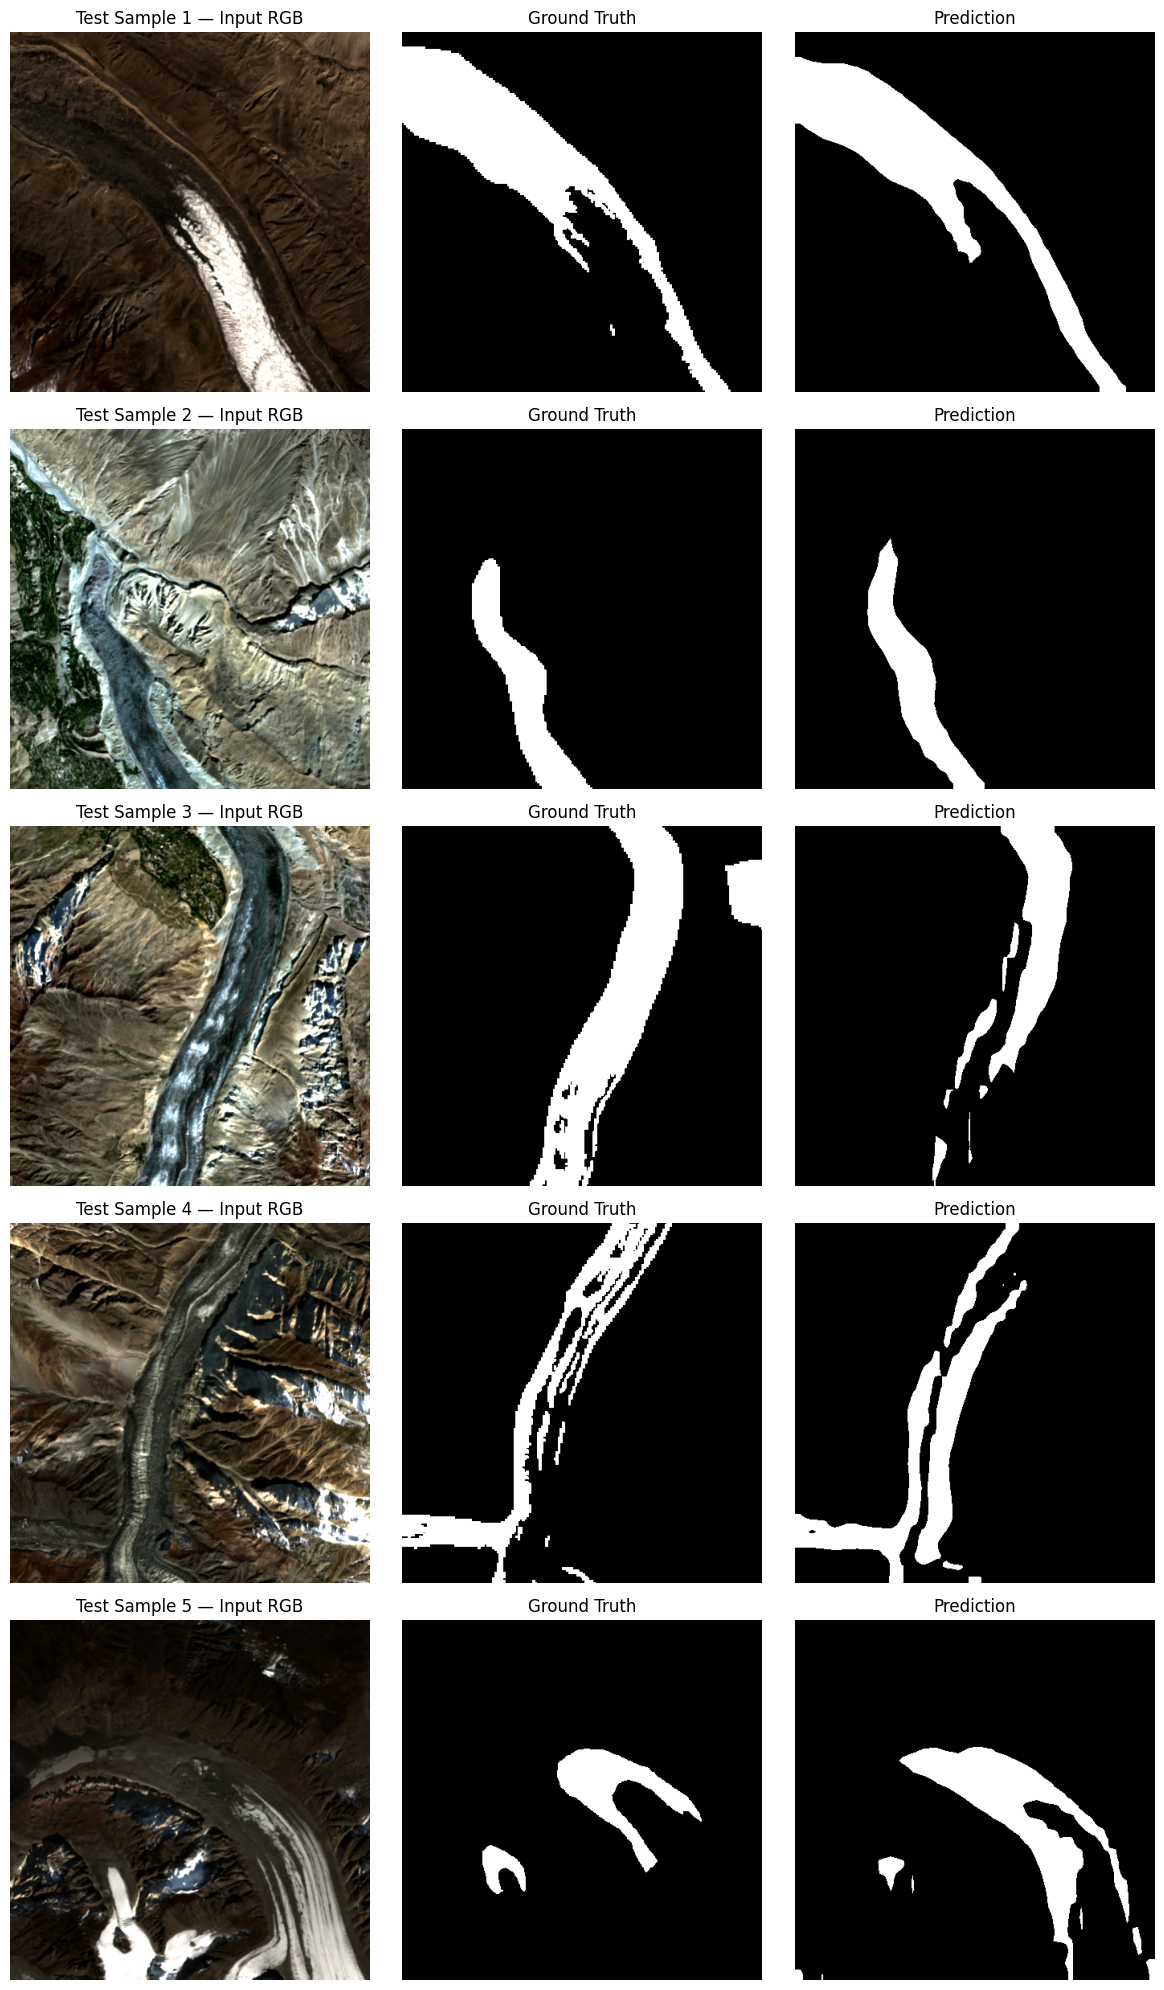

✅ Prediction visualization saved:
/content/drive/MyDrive/Experiment_1_Final/Experiment_1_Predictions.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

net.eval()

fig, axes = plt.subplots(5, 3, figsize=(12, 20))

saved = 0

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)

        logits = net(images)

        predictions = logits.argmax(dim=1)

        # Take first item from batch
        image = images[0].detach().cpu()
        gt = masks[0].detach().cpu().numpy()
        pred = predictions[0].detach().cpu().numpy()

        # ---------------------------------------
        # Make RGB visualization
        # Bands:
        # 0 = Blue
        # 1 = Green
        # 2 = Red
        # ---------------------------------------
        rgb = image[[2, 1, 0]].numpy()
        rgb = np.transpose(rgb, (1, 2, 0))

        # Normalize RGB only for visualization
        rgb_min = np.percentile(rgb, 2)
        rgb_max = np.percentile(rgb, 98)

        rgb = np.clip(
            (rgb - rgb_min) / (rgb_max - rgb_min + 1e-8),
            0,
            1
        )

        # ---------------------------------------
        # Plot
        # ---------------------------------------
        axes[saved, 0].imshow(rgb)
        axes[saved, 0].set_title(f"Test Sample {saved + 1} — Input RGB")
        axes[saved, 0].axis("off")

        axes[saved, 1].imshow(gt, cmap="gray", vmin=0, vmax=1)
        axes[saved, 1].set_title("Ground Truth")
        axes[saved, 1].axis("off")

        axes[saved, 2].imshow(pred, cmap="gray", vmin=0, vmax=1)
        axes[saved, 2].set_title("Prediction")
        axes[saved, 2].axis("off")

        saved += 1

        if saved == 5:
            break

plt.tight_layout()

prediction_path = os.path.join(
    SAVE_DIR,
    "Experiment_1_Predictions.png"
)

plt.savefig(
    prediction_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Prediction visualization saved:")
print(prediction_path)